# Imports

In [1]:
# Get imports and functions needed
%run BaseFiles/Imports.ipynb
%run BaseFiles/Functions.ipynb

# Set global variables
colour1 = "royalblue"
colour2 = "red"


/home/rahyndman/miniforge3/envs/sunpyVenv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-30 11:00:20 - spiceypy.utils.libspicehelper - INFO: Using fallback library next to module: /net/maedoc.ap.dias.ie/maedoc/home_cr/rahyndman/miniforge3/envs/sunpyVenv/lib/python3.14/site-packages/spiceypy/utils/libcspice.so


# Read data from files

In [2]:
# Places to get and save files
DataDirectory = "Data/windData/"
dataName = "wind_min_b"
PlotDirectory = "Plots/WindYearlyPlots/"

# Variables
DataSource = "Wind"
Start  = "1996-01-01 00:00"
End = "1996-02-01 00:00"

#Separated by data source as files may have different file name conventions
if DataSource == "Wind": # If WIND data
    YearlyRange = Yearly(Start, End, frequency = 'MS') #Get range of dates needed # changed to monthly
    print(YearlyRange)
    dataTimeSerieses = [] # empty array for data
    # StartAndEnd = [] # empty array for start and end times
    for i in range(len(YearlyRange)-1): # for each date range in time range needed
        StartDate = YearlyRange[i] # first file in range
        EndDate = YearlyRange[i][0:6] + "31" # last file in range
        # print(StartDate, EndDate)
        # DateRange = ReadDates(StartDate, EndDate) # get date range
        dataFound = FindDataWind(DataDirectory, dataName, StartDate, EndDate) # find data
        dataTS = dfToSeries(dataFound) # convert to timeseries
        dataTS = AddTotVsw(dataTS) # add totvsw
        # dataTS = AddBMag(dataTS) # add bmag
        # dataTS = AddLogBMag(dataTS) 
        # dataTS = AddLogBX(dataTS)
        dataTimeSerieses.append(dataTS) # add to data array
        # StartAndEnd.append([StartDate, EndDate]) # add start and end dates to times array

else: # if not wind (or other coded sources)
    print("Data source not known") # give error message

['19960101', '19960201']


In [3]:
import pandas as pd

data = {
  "testValue": [0, 25, 125, 225, 325, 400, 425, 450, 525, np.nan]
  #"duration": [50, 40, 45]
}

#load data into a DataFrame object:
df = pd.DataFrame(data)

print(df) 

thresMax = 450
thresMin = 400
# TestValue = [0, 25, 125, 225, 325, 400, 425, 450, 525, np.nan]
# TestValue = pd.DataFrame(TestValue)
maskFirst = df["testValue"].between(thresMin, thresMax)
print(maskFirst)


   testValue
0        0.0
1       25.0
2      125.0
3      225.0
4      325.0
5      400.0
6      425.0
7      450.0
8      525.0
9        NaN
0    False
1    False
2    False
3    False
4    False
5     True
6     True
7     True
8    False
9    False
Name: testValue, dtype: bool


# Method 1 : Includes values on threshold

In [4]:
def Method1Calc(Data, Thres, AbsThres, Variable = "TotVsw"):
    maskFirst = Data.to_dataframe()[Variable].between(Thres-AbsThres, Thres+AbsThres) # get true/false array of data based on condition of values being between the threshold values

    StartsPossible = [] # empty array for possible start times
    EndsPossible = [] # empty array for possible end times
    Starts = [] # empty array for nan-filtered start times
    Ends = [] # empty array for nan-filtered end times

    for x in range(len(maskFirst)): # for each point in the dataset
        # print(x, len(maskFirst))
        # if x+1 > len(maskFirst): # if the next point is past the end of the dataset
        #     if maskFirst.values[x] == True: # and this point is in the threshold
        #         EndsPossible.append(maskFirst.index[x]) # add the time to the EndsPossible array
        #     break # then stop the for loop
        if maskFirst.values[x] == True and maskFirst.values[x-1] == False and Data.to_dataframe()[Variable].values[x-1] != np.nan: # if the point exists between the thresholds and the previous point does not, AND the previous point is not a gap
            # start = maskFirst.index[x] # set start variable to the last timestamp that was within the threshold
            StartsPossible.append(maskFirst.index[x]) # add the time to the StartsPossible array
        # if maskFirst.values[x] == True and maskFirst.values[x-1] == True: # if the point exists between the thresholds and the previous point does too
        #     # print("Middle") # print middle (this is for checking the code is doing what we think it is)
        #     pass
        if maskFirst.values[x] == True and maskFirst.values[x+1] == False and Data.to_dataframe()[Variable].values[x+1] != np.nan: # if the point exists between the thresholds and the next point does not, AND the next point is not a gap
            # end = maskFirst.index[x] # set the end variable to the last timestamp that was within the threshold
            EndsPossible.append(maskFirst.index[x]) #  add the time to the EndsPossible array
        # elif maskFirst.values[x] == False: # else if the point does not exist between the thresholds
        #     # print("Not in threshold") # print not in threshold (this is for checking the code is doing what we think it is)

    for y in range(len(StartsPossible)):    
        CheckData = Data.to_dataframe().truncate(StartsPossible[y], EndsPossible[y])
        # print(CheckData[Variable].notna().sum(), CheckData[Variable].isna().sum())
        if CheckData[Variable].notna().sum() >= CheckData[Variable].isna().sum(): #if the amount of non-nans in the steadiness threshold is equal or larger than the amount of nans
            Starts.append(StartsPossible[y]) #then save the start and end times
            Ends.append(EndsPossible[y])


    return StartsPossible, EndsPossible, Starts, Ends

In [5]:
# Daragh's code
# def Method1Calc(Data, Thres, AbsThres, Variable = "TotVsw"):
#     maskFirst = Data.to_dataframe()[Variable].between(Thres-AbsThres, Thres+AbsThres) # get true/false array of data based on condition of values being between the threshold values

#     StartsPossible = [] # empty array for possible start times
#     EndsPossible = [] # empty array for possible end times
#     Starts = [] # empty array for nan-filtered start times
#     Ends = [] # empty array for nan-filtered end times

#     for x in range(len(maskFirst)): # for each point in the dataset
#         if x+1 == len(maskFirst): # if the next point is past the end of the dataset
#             if maskFirst.values[x] == True: # and this point is in the threshold
#                 EndsPossible.append(maskFirst.index[x]) # add the time to the EndsPossible array
#             break # then stop the for loop

#         current_is_true = maskFirst.values[x] == True
#         previous_is_false = maskFirst.values[x-1] == False
#         next_is_false = maskFirst.values[x+1] == False

#         previous_is_nan = np.isnan(Data.to_dataframe()[Variable].values[x-1])
#         next_is_nan = np.isnan(Data.to_dataframe()[Variable].values[x+1])
#         print(previous_is_nan)

#         if current_is_true and previous_is_false and not previous_is_nan:
#             StartsPossible.append(maskFirst.index[x]) # add the time to the StartsPossible array

#         if current_is_true and next_is_false and not next_is_nan:
#             EndsPossible.append(maskFirst.index[x]) #  add the time to the EndsPossible array


#     print(len(StartsPossible))
#     print(len(EndsPossible))
#     for y in range(len(StartsPossible)):  

#         if StartsPossible[y] == EndsPossible[y] or EndsPossible[y] < StartsPossible[y]:
#             continue 
#         CheckData = Data.to_dataframe().truncate(StartsPossible[y], EndsPossible[y])
#         # print(CheckData[Variable].notna().sum(), CheckData[Variable].isna().sum())
#         if CheckData[Variable].notna().sum() >= CheckData[Variable].isna().sum(): #if the amount of non-nans in the steadiness threshold is equal or larger than the amount of nans
#             Starts.append(StartsPossible[y]) #then save the start and end times
#             Ends.append(EndsPossible[y])


#     return StartsPossible, EndsPossible, Starts, Ends


def Method1Plot(Timestart, Timeend, Starts, Ends, Thres, AbsThres, Title = "Total solar wind speed time series", YLabel="Total solar wind speed, km/s", Color = "royalblue", Alpha = 0.05):
    plt.hlines(Thres + AbsThres, xmin = Timestart, xmax = Timeend, color=Color) # plot horizontal lines showing threshold values
    plt.hlines(Thres - AbsThres, xmin = Timestart, xmax = Timeend, color=Color)
    for y in range(len(Starts)): # for each start date (and hopefully each steadiness period)
        plt.axvspan(Starts[y], Ends[y], color = Color, alpha = Alpha) # plot vertical highlighted regions to show where the regions of steadiness are
        # plt.axvspan(starts[y], ends[y], ymin = FirstBaseValue-AbsoluteThreshold, ymax = FirstBaseValue+AbsoluteThreshold, color = "green", alpha = 0.1)

    #General plot settings
    plt.title(Title)
    plt.xlabel("Time")
    plt.ylabel(YLabel)



def Distrib(Starts, Ends, Bins = 50, Variable = "TotVsw", Color="royalblue", Alpha = 0.5):
    # Bins = np.arange(0, 16000, 500)
    tau = []
    for x in range(len(Starts)): # for the length of the Starts array (hopefully equal to the length of the Ends array)
        tau.append(Ends[x]-Starts[x]) # add the duration of each steadiness period
    # print(tau)
    tauInS = []
    for y in range(len(tau)):
        tauInS.append(tau[y].total_seconds()) # change the durations to be in seconds
    # plt.hist(tauInS, bins = Bins, color= Color, alpha=Alpha) # plot the time durations in a histogram
    plt.hist(tauInS, bins = Bins, color= Color, alpha=Alpha) # plot the time durations in a histogram

    #General plot settings
    plt.title("Steadiness timeframes for " + str(Variable))
    plt.xlabel("Steadiness timeframe durations, s")
    plt.ylabel("Frequency")




File not saved


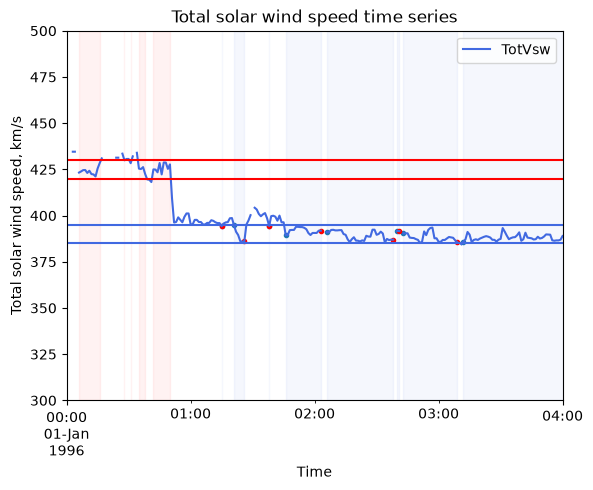

In [6]:
timestart = "1996-01-01 00:00"
timeend = "1996-01-01 04:00"
# timestart = "1996-01-01 00:00"
# timeend = "1996-01-03 00:00"
variable = "TotVsw"
thres1 = 390
absThres1 = 5 # 385-395
color1 = "royalblue"

thres2 = 425
absThres2 = 5 # 395-405
color2 = "red"

fig, ax = plt.subplots()

PlotVsw(dataTimeSerieses[0], Columns=["TotVsw"], XLim =[timestart, timeend], YLim = [300, 500])
plt.ylabel("V_sw, km/s")

startsP1, endsP1, starts1, ends1 = Method1Calc(dataTimeSerieses[0], thres1, absThres1)
startsP2, endsP2, starts2, ends2 = Method1Calc(dataTimeSerieses[0], thres2, absThres2)

# print(len(startsP1), len(starts1))
# print(len(endsP1), len(ends1))
# print(len(startsP2), len(starts2))
# print(len(endsP2), len(ends2))
Method1Plot(timestart, timeend, starts1, ends1, thres1, absThres1, Color=color1)
Method1Plot(timestart, timeend, starts2, ends2, thres2, absThres2, Color=color2)

plt.scatter(startsP1, dataTimeSerieses[0].to_dataframe()["TotVsw"][np.array(startsP1)], marker=".")
plt.scatter(endsP1, dataTimeSerieses[0].to_dataframe()["TotVsw"][np.array(endsP1)], marker=".", color="red")


# # plt.legend(["Steadiness: " + str(thres1-absThres1) + "-"+ str(thres1+absThres1), "Steadiness: " + str(thres2-absThres2) + "-"+ str(thres2+absThres2)])
# # plt.legend()

# print("Caption: Section of time series of solar wind speed with highlighted times that the values stay within the first ("+ str(thres1-absThres1) + "-" + str(thres1+absThres1)+"km/s, "+ color1+")\n and second ("+ str(thres2-absThres2) + "-" + str(thres2+absThres2)+"km/s, "+ color2+") threshold. Highlighted sections are coloured coded to show each threshold.")
# plt.show()

# ############################
# Distrib(starts1, ends1, Color=color1)
# Distrib(starts2, ends2, Color=color2)
# plt.yscale("log")
# print("Caption: Histogram of steadiness timeframes for TotVsw for the first ("+ str(thres1-absThres1) + "-" + str(thres1+absThres1)+"km/s, "+ colour1+") \nand second ("+ str(thres2-absThres2) + "-" + str(thres2+absThres2)+"km/s, "+ colour2+") threshold for first month of 1996.")


In [7]:
print(startsP1[3:5])
print(endsP1[3:5])

[Timestamp('1996-01-01 01:46:00'), Timestamp('1996-01-01 02:06:00')]
[Timestamp('1996-01-01 02:03:00'), Timestamp('1996-01-01 02:38:00')]


In [8]:
print(dataTimeSerieses[0].to_dataframe()["TotVsw"].index[120:150])
print(dataTimeSerieses[0].to_dataframe()["TotVsw"].values[120:150])
print(dataTimeSerieses[0].to_dataframe()["TotVsw"].values[124])
dataTimeSerieses[0].to_dataframe()["TotVsw"].values[124]


DatetimeIndex(['1996-01-01 02:00:00', '1996-01-01 02:01:00',
               '1996-01-01 02:02:00', '1996-01-01 02:03:00',
               '1996-01-01 02:04:00', '1996-01-01 02:05:00',
               '1996-01-01 02:06:00', '1996-01-01 02:07:00',
               '1996-01-01 02:08:00', '1996-01-01 02:09:00',
               '1996-01-01 02:10:00', '1996-01-01 02:11:00',
               '1996-01-01 02:12:00', '1996-01-01 02:13:00',
               '1996-01-01 02:14:00', '1996-01-01 02:15:00',
               '1996-01-01 02:16:00', '1996-01-01 02:17:00',
               '1996-01-01 02:18:00', '1996-01-01 02:19:00',
               '1996-01-01 02:20:00', '1996-01-01 02:21:00',
               '1996-01-01 02:22:00', '1996-01-01 02:23:00',
               '1996-01-01 02:24:00', '1996-01-01 02:25:00',
               '1996-01-01 02:26:00', '1996-01-01 02:27:00',
               '1996-01-01 02:28:00', '1996-01-01 02:29:00'],
              dtype='datetime64[us]', name='DateTime', freq=None)
[390.59754223 390.

np.float64(nan)

# Method 2: does not include values on threshold

- So find timespan (if next one equals nan then move to next one)
    - Then have counters for how many nans (or count after with package)
    - and counters for how many non-nans
    - if nansCount > notNansCount:
        - then don’t add to list of timespans

In [9]:
thresMax = 450
thresMin = 400

TestValue = [0, 25, 125, 225, 325, 400, 425, 450, 525, np.nan]
for i in TestValue:
    if i >= thresMax or i <= thresMin:
        print("Outside Threshold")
    else:
        print("Inside Threshold")


Outside Threshold
Outside Threshold
Outside Threshold
Outside Threshold
Outside Threshold
Outside Threshold
Inside Threshold
Outside Threshold
Outside Threshold
Inside Threshold


In [10]:
def Method2Calc(Timestart, Timeend, Data, RelThres, Variable = "TotVsw"):
    DataShort = Data.truncate(Timestart, Timeend) # Truncate the dataframe for the start and end times
    DataDf = DataShort.to_dataframe() # convert to dataframe

    Starts = [] # create empty array for start times
    Ends = [] # create empty array for end times
    PointTimes = [] # create empty array for time of each measurement
    PointValues = [] # create empty array for value of each measurement
    ThresMaxs = [] # create empty array for time of each measurement
    ThresMins = [] # create empty array for value of each measurement
    PointNanCounter = 0  # create counter for Nans
  
    for i in range(0, len(DataDf[Variable])):
        if str(DataDf[Variable].values[i]) == "nan": # if point has nan values
            # print("Nan")
            PointNanCounter += 1 # add one to the nan counter and move on to the next point

        else:
            # GapNanCounter = 0
            # NotNan = 0
            # NotNan += 1 # add one to the NotNan counter since the data point itself has a value
            Thres = DataDf[Variable].values[i] # set base value for thresholds
            thresMax = Thres + (Thres*RelThres) # max value in threshold
            thresMin = Thres - (Thres*RelThres) # min value in threshold
            ThresMaxs.append(thresMax)
            ThresMins.append(thresMin)
            PointValues.append(DataDf[Variable].values[i]) # add time of measurement to points array
            PointTimes.append(DataDf[Variable].index[i]) # add time of measurement to points array
            # print(Thres)
            # print("Base value = " + str(Thres) + ", ThresMax = " + str(thresMax)+ ", ThresMin = " + str(thresMin)) # print chosen values

            for j in range(1, i): # for values BEFORE this one in the timeseries
                # print("i:" + str(i))
                # print("j:" + str(j))
                if i-j <= 1: # check if you've reached the beginning of your dataset
                    # print("Start of values")
                    # Starts.append(DataDf[Variable].index[0]) # set the start time of this steadiness timeframe to the start timestamp of your dataset
                    start = DataDf[Variable].index[0] # set the start variable of this steadiness timeframe to the start timestamp of your dataset

                    break # end search
                else:
                    if DataDf[Variable].values[i-j] >= thresMax or DataDf[Variable].values[i-j] <= thresMin: #if the value is outside the threshold range
                        # print("Closest neighbour = " + str(j) + " away.") # choose it as the closest neighbour
                        # Starts.append(DataDf[Variable].index[i-j+1]) # set the start time to the last timestamp that was within the threshold
                        start = DataDf[Variable].index[i-j+1] # set start variable to the last timestamp that was within the threshold

                        # if DataDf[Variable].values[i-j] == np.nan: # in the case that this is a data gap (np.nan) add one to the counter
                        #     print("Nan Found")
                        #     GapNanCounter += 1
                        # else:
                        #     print("Not nan")
                        #     NotNan += 1
                        break # end search
                    # else:
                    #     print("Still looking.") # print that you're still looking

            for k in range(1, len(DataDf[Variable])): # for values AFTER this one in the timeseries
                # print("i:" + str(i))
                # print("k:" + str(k))
                # print("i+k:" + str(i+k))
                if i+k >= len(DataDf[Variable]): # check if you've reached the end of your dataset
                    # print("End of values")
                    # Ends.append(DataDf[Variable].index[-1]) # set the ends time of this steadiness timeframe to the end timestamp of your dataset
                    end = DataDf[Variable].index[-1] # set the ends variable of this steadiness timeframe to the end timestamp of your dataset
                    
                    # if DataDf[Variable].values[i-j] == np.nan: # in the case that this is a data gap (np.nan) add one to the counter
                    #     print("Nan Found")
                    #     GapNanCounter += 1
                    # else:
                    #     print("Not nan")
                    #     NotNan += 1

                    break # end search
                else:
                    if DataDf[Variable].values[i+k] >= thresMax or DataDf[Variable].values[i+k] <= thresMin: #if the value is outside the threshold range
                        # print("Closest neighbour = " + str(k) + " away.") # choose it as the closest neighbour
                        # Ends.append(DataDf[Variable].index[i+k-1]) # set the end time to  the last timestamp that was within the threshold
                        end = DataDf[Variable].index[i+k-1] # set the end variable to the last timestamp that was within the threshold
                        break # end search
                    # else:
                    #     print("Still looking.") # print that you're still looking
    
            CheckData = dataTimeSerieses[0].to_dataframe().truncate(start, end)
            if CheckData[Variable].notna().sum() >= CheckData[Variable].isna().sum(): #if the amount of non-nans in the steadiness threshold is equal or larger than the amount of nans
                Starts.append(start) #then save the start and end times
                Ends.append(end)

    # if NotNan >= GapNanCounter:
    #     print("Enough data found")
    #     EnoughData.append(True)
    # else:
    #     print("Not enough data found")
    #     EnoughData.append(False)
    return Starts, Ends, PointValues, PointTimes, ThresMaxs, ThresMins


def Method2Plot(Starts, Ends, PointValues, PointTimes, ThresMaxs, ThresMins, NoOfSections= 10,  Colors=[], All = False, Title = "Total solar wind speed time series", YLabel="Total solar wind speed, km/s", Color = "red", Alpha = 0.05):
    if All == True:
        for i in range(len(Starts)):
            plt.axvspan(Starts[i], Ends[i], color = Color, alpha = Alpha)
    else:
        Range = np.arange(0, len(Starts), round(len(Starts)/NoOfSections))
        j = 0
        for i in Range:
            plt.axvspan(Starts[i], Ends[i], color = Color, alpha = Alpha, zorder=1)
            plt.scatter(PointTimes[i], PointValues[i], color = Color, zorder=3, s=15)
            plt.vlines(Starts[i], ThresMins[i], ThresMaxs[i], color = Color, zorder=2)
            plt.vlines(Ends[i], ThresMins[i], ThresMaxs[i], color = Color, zorder=2)
            plt.hlines(PointValues[i], Starts[i], Ends[i], color = Color, zorder=2)
            j += 1
    # print(len(start))
    # print(len(end))
    # plt.hlines(thresMin, xmin = timestart, xmax = timeend, color=colour1)
    # plt.hlines(thresMax - AbsoluteThreshold, xmin = timestart, xmax = timeend, color=colour1)

    #General plot settings
    plt.title(Title)
    plt.xlabel("Time")
    plt.ylabel(YLabel)


File not saved
Caption: Time series of solar wind speed with highlighted times that the values remain steady for (relative to each data point). 


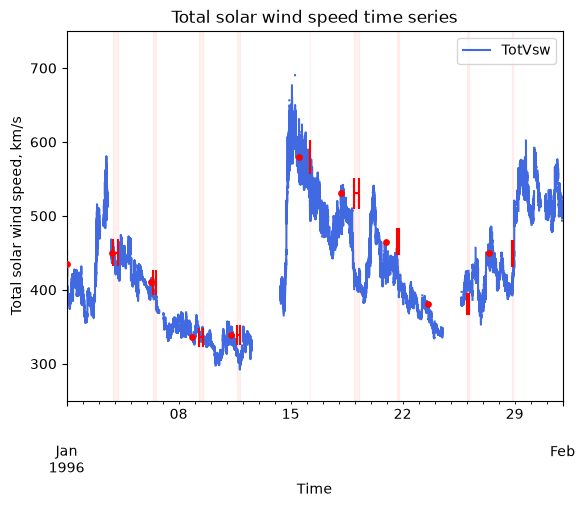

In [11]:
timestart = "1996-01-01 00:00"
timeend = "1996-02-01 00:00"
xlimS = timestart #"1996-01-01 00:00"
xlimE = timeend #"1996-01-01 04:00"
ylimS = 350
ylimE = 550
# testingSeries = dataTimeSerieses[0].truncate(timestart, timeend)
# Thres = 400
relThres = 0.04

# colors = ["red", "orange", "goldenrod", "green", "lightblue", "navy", "purple", "pink", "grey", "black", "white"]
fig, ax = plt.subplots()
# PlotVsw(testingSeries, Columns=["TotVsw"], XLim =[xlimS, xlimE], YLim = [ylimS,ylimE])
PlotVsw(dataTimeSerieses[0], Columns=["TotVsw"], XLim =[timestart, timeend], YLim = [250,750])
startsM2, endsM2, pointvaluesM2, pointtimesM2, thresMaxsM2, thresMinsM2 = Method2Calc(timestart, timeend, dataTimeSerieses[0], relThres)
Method2Plot(startsM2, endsM2, pointvaluesM2, pointtimesM2, thresMaxsM2, thresMinsM2)

print("Caption: Time series of solar wind speed with highlighted times that the values remain steady for (relative to each data point). ")


# Check that nans thing is right

In [12]:
# BEFORE NAN FIX
# print(len(startsM2)) # 34436
# print(len(endsM2)) # 34436

# AFTER NAN FIX
# print(len(startsM2)) # 32448
# print(len(endsM2)) # 32448

difference = 34436-32448
print("Total timespans removed = " + str(difference))
print("Percentance difference = " + str(round(difference/34436 * 100, 2)) + " %")

Total timespans removed = 1988
Percentance difference = 5.77 %


File not saved
Caption: Time series of solar wind speed with highlighted times that the values remain steady for (relative to each data point).


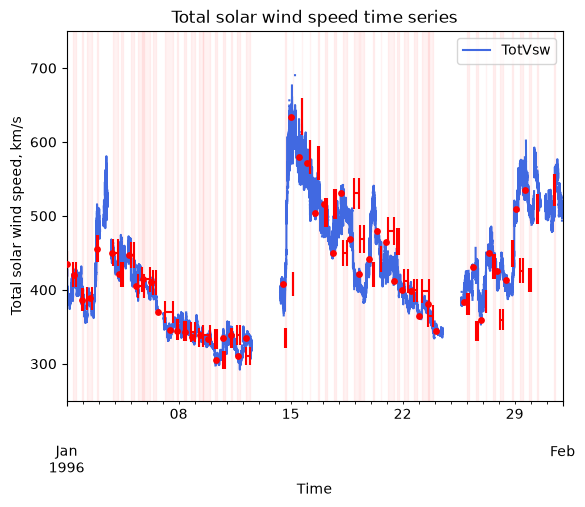

File not saved
Caption: Time series of solar wind speed with highlighted times that the values remain steady for (relative to each data point).


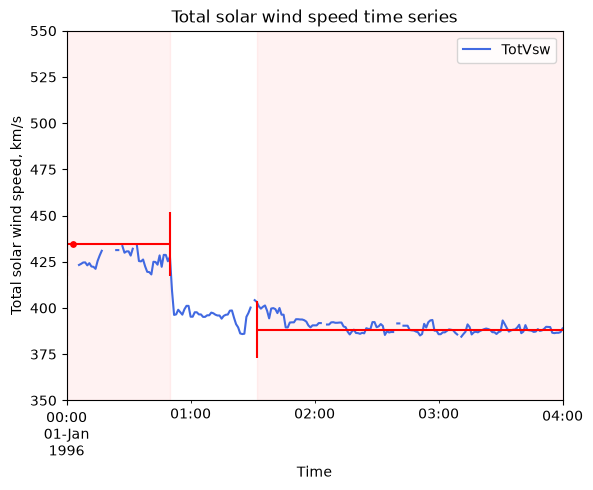

In [13]:
######### Whole month plot ###########
# Just plotting, post-calculations
fig, ax = plt.subplots()
PlotVsw(dataTimeSerieses[0], Columns=["TotVsw"], XLim =[timestart, timeend], YLim = [250,750])
Method2Plot(startsM2, endsM2, pointvaluesM2, pointtimesM2, thresMaxsM2, thresMinsM2, NoOfSections=50)
print("Caption: Time series of solar wind speed with highlighted times that the values remain steady for (relative to each data point).")
plt.show()

######### Zoom into part of the plot ###########
# Just plotting, post-calculations, zoom
# ZoomStart = "1996-01-01 00:00"
# ZoomEnd = "1996-01-03 00:00"
ZoomStart = "1996-01-01 00:00"
ZoomEnd = "1996-01-01 04:00"
fig, ax = plt.subplots()
PlotVsw(dataTimeSerieses[0], Columns=["TotVsw"], XLim =[timestart, timeend], YLim = [ylimS,ylimE])
Method2Plot(startsM2, endsM2, pointvaluesM2, pointtimesM2, thresMaxsM2, thresMinsM2, NoOfSections=100)
plt.xlim(ZoomStart, ZoomEnd)
print("Caption: Time series of solar wind speed with highlighted times that the values remain steady for (relative to each data point).")


# Save data so no recalculation is done at the moment

In [14]:
# import datetime as dt

# ResultsSaved = pd.DataFrame({"Starts":startsM2, "Ends":endsM2, "PointValues":pointvaluesM2, "PointTimes": pointtimesM2, "ThresMaxs":thresMaxsM2, "ThresMins":thresMinsM2})
# ResultsSaved.to_csv("ResultsSaved" + str(dt.datetime.now().date()) + ".csv", index=False)

# Plotting

File not saved
Caption: Time series of solar wind speed with highlighted times that the values remain steady for (relative to each data point).


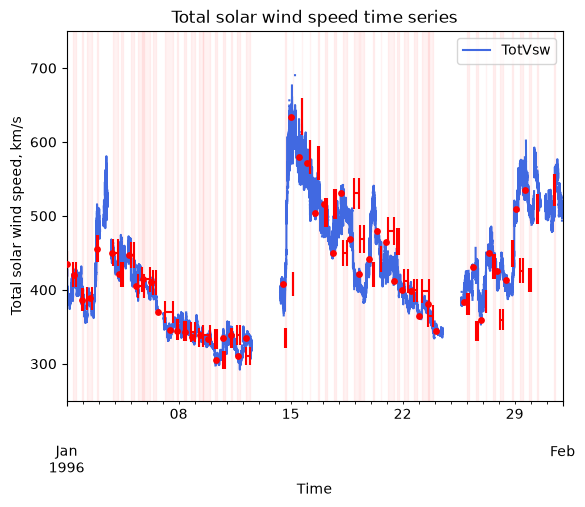

File not saved
Caption: Time series of solar wind speed with highlighted times that the values remain steady for (relative to each data point).


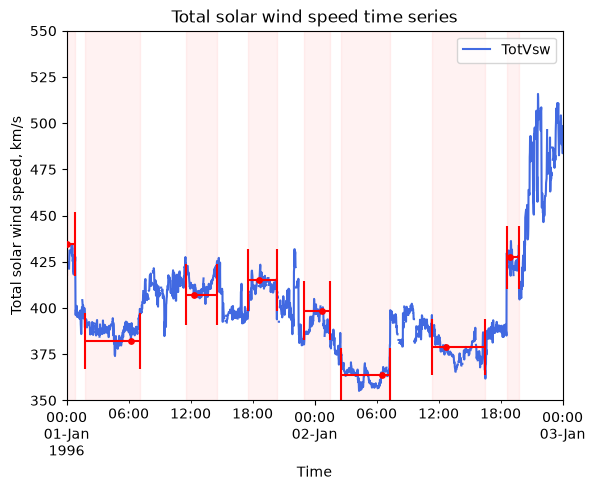

In [15]:
# Read saved file
File = pd.read_csv("ResultsSaved2026-10-19.csv")
# print(File.Ends)


######### Whole month plot ###########
# Just plotting, post-calculations
fig, ax = plt.subplots()
PlotVsw(dataTimeSerieses[0], Columns=["TotVsw"], XLim =[timestart, timeend], YLim = [250,750])
Method2Plot(startsM2, endsM2, pointvaluesM2, pointtimesM2, thresMaxsM2, thresMinsM2, NoOfSections=50)
# Method2Plot(File.Starts, File.Ends, File.PointValues, File.PointTimes, File.ThresMaxs, File.ThresMins, NoOfSections=50)
print("Caption: Time series of solar wind speed with highlighted times that the values remain steady for (relative to each data point).")
plt.show()

######### Zoom into part of the plot ###########
# Just plotting, post-calculations, zoom
ZoomStart = "1996-01-01 00:00"
ZoomEnd = "1996-01-03 00:00"
# ZoomStart = "1996-01-01 00:00"
# ZoomEnd = "1996-01-01 04:00"
fig, ax = plt.subplots()
PlotVsw(dataTimeSerieses[0], Columns=["TotVsw"], XLim =[timestart, timeend], YLim = [ylimS,ylimE])
# Method2Plot(startsM2, endsM2, pointvaluesM2, pointtimesM2, thresMaxsM2, thresMinsM2, NoOfSections=100)
Method2Plot(File.Starts, File.Ends, File.PointValues, File.PointTimes, File.ThresMaxs, File.ThresMins, NoOfSections=100)
plt.xlim(ZoomStart, ZoomEnd)
print("Caption: Time series of solar wind speed with highlighted times that the values remain steady for (relative to each data point).")


In [16]:
# ############################
# Distrib(startsM2, endsM2, Color="red")
# plt.yscale("log")
# print("Caption: Histogram of steadiness timeframes for TotVsw for Method 2.")


In [17]:
# print(testingSeries.to_dataframe()["TotVsw"].index[0])
# print(testingSeries.to_dataframe()["TotVsw"].index[-1])

# print(testingSeries.to_dataframe()["TotVsw"].values[3])
# print(testingSeries.to_dataframe()["TotVsw"].values[2])
# print(testingSeries.to_dataframe()["TotVsw"].values[1])
# print("After")
# print(testingSeries.to_dataframe()["TotVsw"].values[3])
# print(testingSeries.to_dataframe()["TotVsw"].values[4])
# print(testingSeries.to_dataframe()["TotVsw"].values[5])
# print(testingSeries.to_dataframe()["TotVsw"].values[6])
# print(testingSeries.to_dataframe()["TotVsw"].values[7])
# print(testingSeries.to_dataframe()["TotVsw"].values[8])

# basevalue = testingSeries.to_dataframe()["TotVsw"].values[3] # set base value
# thresMax = basevalue + (basevalue*RelativeThreshold) # add threshold
# thresMin = basevalue - (basevalue*RelativeThreshold) # minus threshold
# print(basevalue, thresMax, thresMin)

# for checking in range(0,55):
#     if testingSeries.to_dataframe()["TotVsw"].values[checking] >= thresMax or testingSeries.to_dataframe()["TotVsw"].values[checking] <= thresMin:
#         print("Yes")
#         print(checking)
#     else:
#         print(checking)
#         print(testingSeries.to_dataframe()["TotVsw"].values[checking])
#         print("No")

# print("start")
# print(start)
# print(basetime)
# print(end)
# print(len(start))
# print(len(basetime))
# print(len(end))

In [18]:
# print(testingSeries.to_dataframe()["TotVsw"].index)

In [19]:
# timestart = "1996-01-01 00:00"
# timeend = "1996-01-03 00:00"
# xlimS = timestart #"1996-01-01 00:00"
# xlimE = timeend #"1996-01-01 04:00"
# ylimS = 350
# ylimE = 550

# testingSeries = dataTimeSerieses[0].truncate(timestart, timeend)
# fig, ax = plt.subplots()

# # PlotVsw(dataTimeSerieses[0], Columns=["TotVsw"], XLim =[timestart, timeend], YLim = [200,800])
# PlotVsw(testingSeries, Columns=["TotVsw"], XLim =[xlimS, xlimE], YLim = [ylimS,ylimE])

# Alpha = 0.1
# RelativeThreshold = 0.05

# from datetime import datetime, timedelta

# tooShort = 0

# for a in range(len(start)):
#     # print(len(start))
#     # print(len(end))
#     # print(a)
#     # print(a*10)

#     if end[a] - start[a] < timedelta(minutes=60):
#         tooShort += 1
#     elif a <= len(start):
#         plt.axvspan(start[a], end[a], color = colour1, alpha = Alpha)
#     else:
#         break

# # plt.hlines(thresMin, xmin = timestart, xmax = timeend, color=colour1)
# # plt.hlines(thresMax - AbsoluteThreshold, xmin = timestart, xmax = timeend, color=colour1)


# #General plot settings
# plt.title("Total solar wind speed time series")
# plt.xlabel("Time")
# plt.ylabel("Total solar wind speed, km/s")
# # print("Caption: Time series of solar wind speed with highlighted times that the values stay within the first ("+ str(FirstBaseValue-AbsoluteThreshold) + "-" + str(FirstBaseValue+AbsoluteThreshold)+"km/s, "+ colour1+")\n and second ("+ str(SecondBaseValue-AbsoluteThreshold) + "-" + str(SecondBaseValue+AbsoluteThreshold)+"km/s, "+ colour2+") threshold. Highlighted sections are coloured coded to show each threshold.")

# New version saved

# Changepoint detection method

In [20]:
def CUSUM(y, c, var):
    n = len(y)
    C_max = 0
    Tau_hat = 0
    S_n = sum(y)
    S = 0

    AllScores = []
    
    for t in range(1, n-1):
        S = S + y[t]
        ybar_1t = S/t
        ybar_t1n = (S_n-S)/(n-t)
        C2_t = (t*(n-t)/n)*(ybar_1t-ybar_t1n)**2
        AllScores.append(C2_t/var)
        if C2_t > C_max:
            C_max = C2_t
            Tau_hat = t

    if C_max/var > c:
        return Tau_hat, C_max, AllScores
    else:
        Null = np.nan
        return Null, C_max, AllScores

1503.5124653739615
3 5379.632675438596
150
[np.float64(0.050410222333585525), np.float64(0.14789002039220306), np.float64(3.578043281537108), np.float64(2.646959658638681), np.float64(1.7920187683451172), np.float64(1.2591410590878134), np.float64(1.0535480036721816), np.float64(0.7908514570430895), np.float64(0.5526489730009464), np.float64(0.44448004385749434), np.float64(2.3819060772323954), np.float64(2.0705237517950312), np.float64(0.6196129649197994), np.float64(0.4763662243484192), np.float64(0.4245082920633983), np.float64(0.2940665179843566), np.float64(0.19571919797603912)]


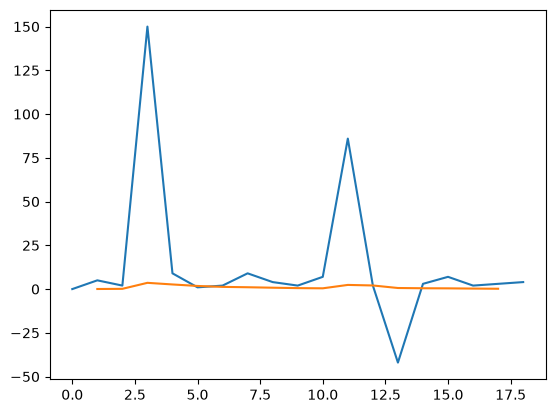

In [21]:
y = [0,5,2,150,9,1,2,9,4,2,7,86,2,-42,3,7,2,3,4]
x = np.arange(0, len(y))
plt.plot(x, y)
Tau_hat, C_max, AllScores = CUSUM(y, 2, np.var(y))
print(np.var(y))

print(Tau_hat, C_max)
print(y[Tau_hat])

print(AllScores)

plt.plot(x[1:-1], AllScores)

In [22]:
y = dataTimeSerieses[0].to_dataframe()["TotVsw"].values
print(y)

[         nan          nan          nan ... 506.60268456 507.30099547
 507.1003944 ]


5618.511653335351
15121 61653518.234834775
320.3476080759774
[np.float64(0.01924283440319775), np.float64(0.008052029128337673), np.float64(0.005043761229443229), np.float64(0.004153332275868026), np.float64(0.003672904622925048), np.float64(0.0024342698443808033), np.float64(0.002133540669757797), np.float64(0.0012368574631976843), np.float64(0.0006116127810051247), np.float64(0.00011794824759632048), np.float64(0.00024289294219095376), np.float64(0.0009742770449351044), np.float64(0.003032946329688361), np.float64(0.0061809307468039115), np.float64(0.010127893248885746), np.float64(0.016542095099099485), np.float64(0.02054036554663206), np.float64(0.02548592639417227), np.float64(0.030695186954708225), np.float64(0.03358253581488468), np.float64(0.04072883535502441), np.float64(0.0506679379983535), np.float64(0.049991698828173975), np.float64(0.04915002209763837), np.float64(0.04960238386905506), np.float64(0.04581092394205289), np.float64(0.03929243612175397), np.float64(0.033358578

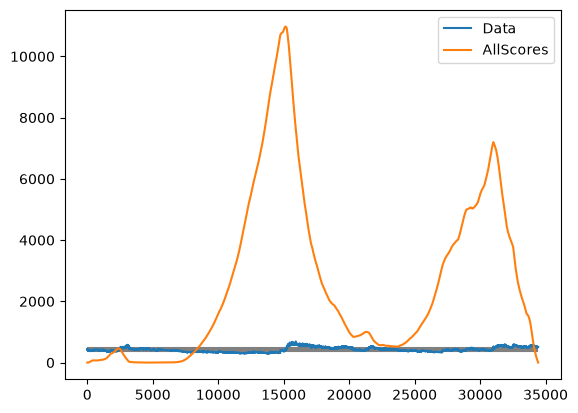

In [23]:
y = dataTimeSerieses[0].to_dataframe()["TotVsw"].values
x = np.arange(0, len(y))

# plt.plot(x, y, label="Data")

cleanedList = [x for x in y if str(x) != 'nan']
print(np.var(cleanedList))
x = np.arange(0, len(cleanedList))

plt.plot(x, cleanedList, label="Data")
Tau_hat, C_max, AllScores = CUSUM(cleanedList, 50, np.var(cleanedList))

plt.hlines(np.mean(cleanedList), 0, len(x), color="grey", zorder=0)
plt.hlines(np.mean(cleanedList)+50, 0, len(x), color="grey", zorder=0)
plt.hlines(np.mean(cleanedList)-50, 0, len(x), color="grey", zorder=0)

print(Tau_hat, C_max)
print(y[Tau_hat])

print(AllScores)

AllScoresAdj = []
for a in AllScores:
    AllScoresAdj.append((a/50)+400)

plt.plot(x[1:-1], AllScores, label="AllScores")
# plt.plot(x[1:-1], AllScoresAdj, label="AllScores")

plt.legend()

# Code resampling and taking basic version of steadiness

In [24]:
# Places to get and save files
DataDirectory = "Data/windData/"
dataName = "wind_min_b"
PlotDirectory = "Plots/WindYearlyPlots/"


In [25]:

# Variables
DataSource = "Wind"
Start  = "1996-01-01 00:00"
End = "1996-02-01 00:00"


In [26]:

#Separated by data source as files may have different file name conventions
if DataSource == "Wind": # If WIND data
    YearlyRange = Yearly(Start, End, frequency = 'MS') #Get range of dates needed # changed to monthly
    print(YearlyRange)
    dataTimeSerieses = [] # empty array for data
    # StartAndEnd = [] # empty array for start and end times
    for i in range(len(YearlyRange)-1): # for each date range in time range needed
        StartDate = YearlyRange[i] # first file in range
        EndDate = YearlyRange[i][0:6] + "31" # last file in range
        # print(StartDate, EndDate)
        # DateRange = ReadDates(StartDate, EndDate) # get date range
        dataFound = FindDataWind(DataDirectory, dataName, StartDate, EndDate) # find data
        dataTS = dfToSeries(dataFound) # convert to timeseries
        dataTS = AddTotVsw(dataTS) # add totvsw
        # dataTS = AddBMag(dataTS) # add bmag
        # dataTS = AddLogBMag(dataTS) 
        # dataTS = AddLogBX(dataTS)
        dataTimeSerieses.append(dataTS) # add to data array
        # StartAndEnd.append([StartDate, EndDate]) # add start and end dates to times array

else: # if not wind (or other coded sources)
    print("Data source not known") # give error message


['19960101', '19960201']


In [27]:
# Resample data - Choose a resample rate that seems accurate to changes in data

rate = "1h"
# print(dataTimeSerieses[0])
resampled = dataTimeSerieses[0].to_dataframe().resample(rate, label="right").mean() 
# print(resampled)
resampledTS = TimeSeries(resampled)
# print(resampledTS)

rate2 = "2h"
# print(dataTimeSerieses[0])
resampled2 = dataTimeSerieses[0].to_dataframe().resample(rate2, label="right").mean() 
# print(resampled2)
resampledTS2 = TimeSeries(resampled2)
# print(resampledTS2)


File not saved
File not saved
Variance of raw data = 5618.674816153802
Variance of resampled (1h) data = 5534.4558497060625
Variance of resampled (2h) data = 5474.9214019563315
DateTime
1996-01-01 00:00:00         NaN
1996-01-01 00:01:00         NaN
1996-01-01 00:02:00         NaN
1996-01-01 00:03:00         NaN
1996-01-01 00:04:00    0.000000
                         ...   
1996-01-31 23:55:00    2.903463
1996-01-31 23:56:00   -4.299708
1996-01-31 23:57:00    2.196003
1996-01-31 23:58:00    0.698311
1996-01-31 23:59:00   -0.200601
Name: TotVsw, Length: 44640, dtype: float64
DateTime
1996-01-01 01:00:00          NaN
1996-01-01 02:00:00   -26.096192
1996-01-01 03:00:00    -6.067082
1996-01-01 04:00:00    -1.541113
1996-01-01 05:00:00    -3.089782
                         ...    
1996-01-31 20:00:00    12.775380
1996-01-31 21:00:00    -5.578707
1996-01-31 22:00:00    -9.700978
1996-01-31 23:00:00    -4.367926
1996-02-01 00:00:00    -2.218920
Freq: h, Name: TotVsw, Length: 744, dtype: flo

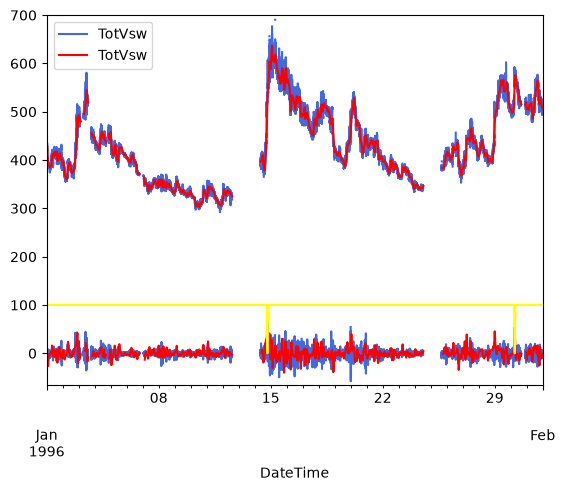

In [28]:
Columns = ["TotVsw"]#, "Vx_GSE", "Vy_GSE", "Vz_GSE"]
# xlim = [Start, End]
ZoomStart = "1996-01-01 00:00"
ZoomEnd = "1996-01-01 04:00"
xlim = [ZoomStart, ZoomEnd]
# ylim = [250, 700]
ylim = [-65, 700]
color3 = "yellow"

fig, ax = plt.subplots()
# Plot timeseries with raw data
PlotVsw(dataTimeSerieses[0], Columns=["TotVsw"], XLim = xlim, YLim = ylim, Color = color1, Label = "Raw data")

# Plot timeseries with resampled data
PlotVsw(resampledTS, Columns=["TotVsw"], XLim = xlim, YLim = ylim, Color = color2, Label = "Resampled at " + rate)
# PlotVsw(resampledTS2, Columns=["TotVsw"], XLim = xlim, YLim = ylim, Color = color3, Label = "Resampled at " + rate2)

# PlotVsw(dataTimeSerieses[0].resample("5min").sum(), Columns=["TotVsw"], XLim = xlim) # .sum() or no?

# Calculate variance of data
dataTimeSeriesVar = dataTimeSerieses[0].to_dataframe()["TotVsw"].var()
print( "Variance of raw data = " + str(dataTimeSeriesVar))
dataTimeSeriesVar = resampled["TotVsw"].var()
print( "Variance of resampled (" + rate + ") data = " + str(dataTimeSeriesVar))
dataTimeSeriesVar = resampled2["TotVsw"].var()
print( "Variance of resampled (" + rate2 + ") data = " + str(dataTimeSeriesVar))

# Plot "derivative" of data

Diff = dataTimeSerieses[0].to_dataframe()["TotVsw"].diff()
DiffResampled = resampled["TotVsw"].diff()
print(Diff)
print(DiffResampled)


Diff.plot(color=color1)
DiffResampled.plot(color=color2)

ThresholdOfChange = 50
# DiffSteadyOrNot = Diff.where(abs(Diff) < ThresholdOfChange, "notsteady") # .where() replaces where the condition is NOT met (False)
# DiffSteadyOrNot = DiffSteadyOrNot.where(abs(Diff) > ThresholdOfChange, "steady")
# # DiffSteadyOrNot = DiffSteadyOrNot.where(abs(Diff) != np.nan, "nan") # get nans back
DiffSteadyOrNot = Diff.where(abs(Diff) < ThresholdOfChange, 0) # .where() replaces where the condition is NOT met (False)
DiffSteadyOrNot = DiffSteadyOrNot.where(abs(Diff) > ThresholdOfChange, 1)
print(DiffSteadyOrNot)

# DiffResampledSteadyOrNot = DiffResampled.where(abs(DiffResampled) < ThresholdOfChange, "notsteady") # .where() replaces where the condition is NOT met (False)
# DiffResampledSteadyOrNot = DiffResampledSteadyOrNot.where(abs(DiffResampled) > ThresholdOfChange, "steady")
# # DiffResampledSteadyOrNot = DiffResampledSteadyOrNot.where(abs(DiffResampled) != np.nan, "nan") # get nans back
DiffResampledSteadyOrNot = DiffResampled.where(abs(DiffResampled) < ThresholdOfChange, 0) # .where() replaces where the condition is NOT met (False)
DiffResampledSteadyOrNot = DiffResampledSteadyOrNot.where(abs(DiffResampled) > ThresholdOfChange, 1)
print(DiffResampledSteadyOrNot)

DiffResampledSteadyOrNotAdj = DiffResampledSteadyOrNot*100
DiffResampledSteadyOrNotAdj.plot(color="yellow")


print( "unique values = " + str(DiffResampledSteadyOrNotAdj.value_counts()))
# DiffAdj = []
# for i in range(len(Diff)):
#     diffAdj = Diff.values[i] + (dataTimeSerieses[0].to_dataframe()["TotVsw"].mean())
#     DiffAdj.append(diffAdj)

# DiffAdj.plot()



# derivative = []
# # dataToDerive = dataTimeSerieses[0].to_dataframe()["TotVsw"]
# dataToDerive = resampled["TotVsw"]
# # dataToDerive = resampled2["TotVsw"]

# for i in range(len(dataToDerive)-1):
#     y_diff = dataToDerive.values[i+1]-dataToDerive.values[i]
#     derivative.append(y_diff)


# # derivative10 = []
# d = {"TotVswDev": derivative}
# derivative = pd.DataFrame(data=d, index=dataToDerive.index[0:-1])
# print(derivative)
# ax.plot(derivative, markersize=10)
# # derivative.plot()
# # for j in range(len(derivative)):
# #     derivative10.append(derivative[j]*10)

# # derivative.plot() # , alpha = 0.5)
# # PlotVsw(derivative["TotVswDev"],  XLim = xlim, YLim = ylim, Color = color1, Label = "Raw data")
# # plt.plot(dataToDerive.index[0:-1], derivative, color="green")


# print("Caption: Raw data ("+str(color1) + ") and data resampled at " + rate + " resample rate ("+str(color2) + ") and "+ rate2 + " resample rate ("+str(color3) + ").")





# At maximum

In [29]:
# Places to get and save files
DataDirectory = "Data/windData/"
dataName = "wind_min_b"
PlotDirectory = "Plots/WindYearlyPlots/"


In [30]:

# Variables
DataSource = "Wind"
Start  = "2000-06-01 00:00"
End = "2000-07-01 00:00"


In [31]:

#Separated by data source as files may have different file name conventions
if DataSource == "Wind": # If WIND data
    YearlyRange = Yearly(Start, End, frequency = 'MS') #Get range of dates needed # changed to monthly
    print(YearlyRange)
    dataTimeSerieses = [] # empty array for data
    # StartAndEnd = [] # empty array for start and end times
    for i in range(len(YearlyRange)-1): # for each date range in time range needed
        StartDate = YearlyRange[i] # first file in range
        if YearlyRange[i][4:6] == "01" or YearlyRange[i][4:6] == "03" or YearlyRange[i][4:6] == "05" or YearlyRange[i][4:6] == "07":
            EndDate = YearlyRange[i][0:6] + "31" # last file in range
        elif YearlyRange[i][4:6] == "02":
            EndDate = YearlyRange[i][0:6] + "29" # last file in range
        elif YearlyRange[i][4:6] == "04" or YearlyRange[i][4:6] == "06" or YearlyRange[i][4:6] == "08":
                EndDate = YearlyRange[i][0:6] + "30" # last file in range
        # print(StartDate, EndDate)
        # DateRange = ReadDates(StartDate, EndDate) # get date range
        dataFound = FindDataWind(DataDirectory, dataName, StartDate, EndDate) # find data
        dataTS = dfToSeries(dataFound) # convert to timeseries
        dataTS = AddTotVsw(dataTS) # add totvsw
        # dataTS = AddBMag(dataTS) # add bmag
        # dataTS = AddLogBMag(dataTS) 
        # dataTS = AddLogBX(dataTS)
        dataTimeSerieses.append(dataTS) # add to data array
        # StartAndEnd.append([StartDate, EndDate]) # add start and end dates to times array

else: # if not wind (or other coded sources)
    print("Data source not known") # give error message


['20000601', '20000701']


In [32]:
# Resample data - Choose a resample rate that seems accurate to changes in data

rate = "1h"
# print(dataTimeSerieses[0])
resampled = dataTimeSerieses[0].to_dataframe().resample(rate, label="right").mean() 
# print(resampled)
resampledTS = TimeSeries(resampled)
# print(resampledTS)

rate2 = "2h"
# print(dataTimeSerieses[0])
resampled2 = dataTimeSerieses[0].to_dataframe().resample(rate2, label="right").mean() 
# print(resampled2)
resampledTS2 = TimeSeries(resampled2)
# print(resampledTS2)


File not saved
File not saved
Variance of raw data = 5637.240434991073
Variance of resampled (1h) data = 5442.308308061471
Variance of resampled (2h) data = 5581.324188640271
DateTime
2000-06-01 00:00:00          NaN
2000-06-01 00:01:00     6.282770
2000-06-01 00:02:00   -14.603672
2000-06-01 00:03:00    11.316637
2000-06-01 00:04:00    -5.682817
                         ...    
2000-06-30 23:55:00          NaN
2000-06-30 23:56:00          NaN
2000-06-30 23:57:00          NaN
2000-06-30 23:58:00     0.000000
2000-06-30 23:59:00     0.000000
Name: TotVsw, Length: 43200, dtype: float64
DateTime
2000-06-01 01:00:00          NaN
2000-06-01 02:00:00    -0.150429
2000-06-01 03:00:00    26.230158
2000-06-01 04:00:00   -13.617836
2000-06-01 05:00:00    -3.605912
                         ...    
2000-06-30 20:00:00     7.835255
2000-06-30 21:00:00    -8.110345
2000-06-30 22:00:00   -11.743474
2000-06-30 23:00:00     7.250561
2000-07-01 00:00:00    14.725155
Freq: h, Name: TotVsw, Length: 720, d

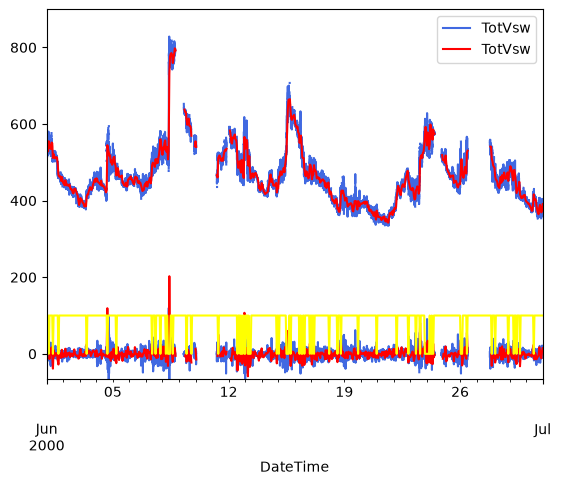

In [33]:
Columns = ["TotVsw"]#, "Vx_GSE", "Vy_GSE", "Vz_GSE"]
# xlim = [Start, End]
ZoomStart = "2000-01-01 00:00"
ZoomEnd = "2000-01-01 04:00"
xlim = [ZoomStart, ZoomEnd]
# ylim = [250, 700]
ylim = [-65, 900]
color3 = "yellow"

fig, ax = plt.subplots()
# Plot timeseries with raw data
PlotVsw(dataTimeSerieses[0], Columns=["TotVsw"], XLim = xlim, YLim = ylim, Color = color1, Label = "Raw data")

# Plot timeseries with resampled data
PlotVsw(resampledTS, Columns=["TotVsw"], XLim = xlim, YLim = ylim, Color = color2, Label = "Resampled at " + rate)
# PlotVsw(resampledTS2, Columns=["TotVsw"], XLim = xlim, YLim = ylim, Color = color3, Label = "Resampled at " + rate2)

# PlotVsw(dataTimeSerieses[0].resample("5min").sum(), Columns=["TotVsw"], XLim = xlim) # .sum() or no?

# Calculate variance of data
dataTimeSeriesVar = dataTimeSerieses[0].to_dataframe()["TotVsw"].var()
print( "Variance of raw data = " + str(dataTimeSeriesVar))
dataTimeSeriesVar = resampled["TotVsw"].var()
print( "Variance of resampled (" + rate + ") data = " + str(dataTimeSeriesVar))
dataTimeSeriesVar = resampled2["TotVsw"].var()
print( "Variance of resampled (" + rate2 + ") data = " + str(dataTimeSeriesVar))

# Plot "derivative" of data

Diff = dataTimeSerieses[0].to_dataframe()["TotVsw"].diff()
DiffResampled = resampled["TotVsw"].diff()
print(Diff)
print(DiffResampled)


Diff.plot(color=color1)
DiffResampled.plot(color=color2)

ThresholdOfChange = 20
# DiffSteadyOrNot = Diff.where(abs(Diff) < ThresholdOfChange, "notsteady") # .where() replaces where the condition is NOT met (False)
# DiffSteadyOrNot = DiffSteadyOrNot.where(abs(Diff) > ThresholdOfChange, "steady")
# # DiffSteadyOrNot = DiffSteadyOrNot.where(abs(Diff) != np.nan, "nan") # get nans back
DiffSteadyOrNot = Diff.where(abs(Diff) < ThresholdOfChange, 0) # .where() replaces where the condition is NOT met (False)
DiffSteadyOrNot = DiffSteadyOrNot.where(abs(Diff) > ThresholdOfChange, 1)
print(DiffSteadyOrNot)

# DiffResampledSteadyOrNot = DiffResampled.where(abs(DiffResampled) < ThresholdOfChange, "notsteady") # .where() replaces where the condition is NOT met (False)
# DiffResampledSteadyOrNot = DiffResampledSteadyOrNot.where(abs(DiffResampled) > ThresholdOfChange, "steady")
# # DiffResampledSteadyOrNot = DiffResampledSteadyOrNot.where(abs(DiffResampled) != np.nan, "nan") # get nans back
DiffResampledSteadyOrNot = DiffResampled.where(abs(DiffResampled) < ThresholdOfChange, 0) # .where() replaces where the condition is NOT met (False)
DiffResampledSteadyOrNot = DiffResampledSteadyOrNot.where(abs(DiffResampled) > ThresholdOfChange, 1)
print(DiffResampledSteadyOrNot)

DiffResampledSteadyOrNotAdj = DiffResampledSteadyOrNot*100
DiffResampledSteadyOrNotAdj.plot(color="yellow")


print( "unique values = " + str(DiffResampledSteadyOrNotAdj.value_counts()))
# DiffAdj = []
# for i in range(len(Diff)):
#     diffAdj = Diff.values[i] + (dataTimeSerieses[0].to_dataframe()["TotVsw"].mean())
#     DiffAdj.append(diffAdj)

# DiffAdj.plot()



# derivative = []
# # dataToDerive = dataTimeSerieses[0].to_dataframe()["TotVsw"]
# dataToDerive = resampled["TotVsw"]
# # dataToDerive = resampled2["TotVsw"]

# for i in range(len(dataToDerive)-1):
#     y_diff = dataToDerive.values[i+1]-dataToDerive.values[i]
#     derivative.append(y_diff)


# # derivative10 = []
# d = {"TotVswDev": derivative}
# derivative = pd.DataFrame(data=d, index=dataToDerive.index[0:-1])
# print(derivative)
# ax.plot(derivative, markersize=10)
# # derivative.plot()
# # for j in range(len(derivative)):
# #     derivative10.append(derivative[j]*10)

# # derivative.plot() # , alpha = 0.5)
# # PlotVsw(derivative["TotVswDev"],  XLim = xlim, YLim = ylim, Color = color1, Label = "Raw data")
# # plt.plot(dataToDerive.index[0:-1], derivative, color="green")


# print("Caption: Raw data ("+str(color1) + ") and data resampled at " + rate + " resample rate ("+str(color2) + ") and "+ rate2 + " resample rate ("+str(color3) + ").")





# At minimum

In [34]:
# Places to get and save files
DataDirectory = "Data/windData/"
dataName = "wind_min_b"
PlotDirectory = "Plots/WindYearlyPlots/"


In [35]:

# Variables
DataSource = "Wind"
Start  = "1996-06-01 00:00"
End = "1996-07-01 00:00"


In [36]:

#Separated by data source as files may have different file name conventions
if DataSource == "Wind": # If WIND data
    YearlyRange = Yearly(Start, End, frequency = 'MS') #Get range of dates needed # changed to monthly
    print(YearlyRange)
    dataTimeSerieses = [] # empty array for data
    # StartAndEnd = [] # empty array for start and end times
    for i in range(len(YearlyRange)-1): # for each date range in time range needed
        StartDate = YearlyRange[i] # first file in range
        if YearlyRange[i][4:6] == "01" or YearlyRange[i][4:6] == "03" or YearlyRange[i][4:6] == "05" or YearlyRange[i][4:6] == "07":
            EndDate = YearlyRange[i][0:6] + "31" # last file in range
        elif YearlyRange[i][4:6] == "02":
            EndDate = YearlyRange[i][0:6] + "29" # last file in range
        elif YearlyRange[i][4:6] == "04" or YearlyRange[i][4:6] == "06" or YearlyRange[i][4:6] == "08":
                EndDate = YearlyRange[i][0:6] + "30" # last file in range
        # print(StartDate, EndDate)
        # DateRange = ReadDates(StartDate, EndDate) # get date range
        dataFound = FindDataWind(DataDirectory, dataName, StartDate, EndDate) # find data
        dataTS = dfToSeries(dataFound) # convert to timeseries
        dataTS = AddTotVsw(dataTS) # add totvsw
        # dataTS = AddBMag(dataTS) # add bmag
        # dataTS = AddLogBMag(dataTS) 
        # dataTS = AddLogBX(dataTS)
        dataTimeSerieses.append(dataTS) # add to data array
        # StartAndEnd.append([StartDate, EndDate]) # add start and end dates to times array

else: # if not wind (or other coded sources)
    print("Data source not known") # give error message


['19960601', '19960701']


In [37]:
# Resample data - Choose a resample rate that seems accurate to changes in data

rate = "1h"
# print(dataTimeSerieses[0])
resampled = dataTimeSerieses[0].to_dataframe().resample(rate, label="right").mean() 
# print(resampled)
resampledTS = TimeSeries(resampled)
# print(resampledTS)

rate2 = "2h"
# print(dataTimeSerieses[0])
resampled2 = dataTimeSerieses[0].to_dataframe().resample(rate2, label="right").mean() 
# print(resampled2)
resampledTS2 = TimeSeries(resampled2)
# print(resampledTS2)


File not saved
File not saved
Variance of raw data = 1680.0279445182925
Variance of resampled (1h) data = 1669.6038084496151
Variance of resampled (2h) data = 1657.0670481870395
DateTime
1996-06-01 00:00:00    NaN
1996-06-01 00:01:00    NaN
1996-06-01 00:02:00    NaN
1996-06-01 00:03:00    0.0
1996-06-01 00:04:00    0.0
                      ... 
1996-06-30 23:55:00    NaN
1996-06-30 23:56:00    NaN
1996-06-30 23:57:00    NaN
1996-06-30 23:58:00    NaN
1996-06-30 23:59:00    0.0
Name: TotVsw, Length: 43200, dtype: float64
DateTime
1996-06-01 01:00:00          NaN
1996-06-01 02:00:00     7.968825
1996-06-01 03:00:00          NaN
1996-06-01 04:00:00          NaN
1996-06-01 05:00:00          NaN
                         ...    
1996-06-30 20:00:00     4.151094
1996-06-30 21:00:00    18.054562
1996-06-30 22:00:00    20.816307
1996-06-30 23:00:00   -16.729335
1996-07-01 00:00:00    -1.195418
Freq: h, Name: TotVsw, Length: 720, dtype: float64
DateTime
1996-06-01 00:00:00    1.0
1996-06-01 00

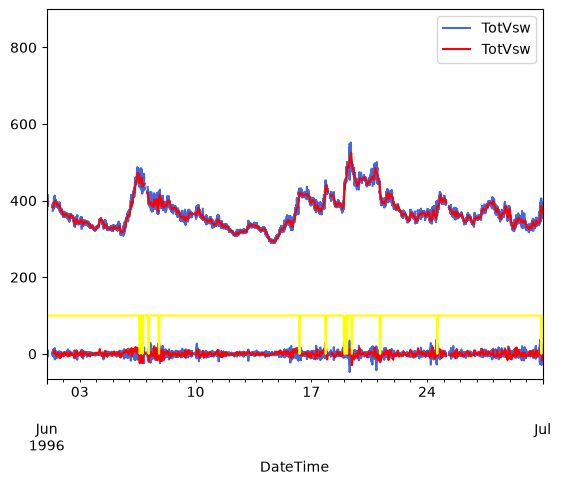

In [38]:
Columns = ["TotVsw"]#, "Vx_GSE", "Vy_GSE", "Vz_GSE"]
# xlim = [Start, End]
ZoomStart = "2000-01-01 00:00"
ZoomEnd = "2000-01-01 04:00"
xlim = [ZoomStart, ZoomEnd]
# ylim = [250, 700]
ylim = [-65, 900]
color3 = "yellow"

fig, ax = plt.subplots()
# Plot timeseries with raw data
PlotVsw(dataTimeSerieses[0], Columns=["TotVsw"], XLim = xlim, YLim = ylim, Color = color1, Label = "Raw data")

# Plot timeseries with resampled data
PlotVsw(resampledTS, Columns=["TotVsw"], XLim = xlim, YLim = ylim, Color = color2, Label = "Resampled at " + rate)
# PlotVsw(resampledTS2, Columns=["TotVsw"], XLim = xlim, YLim = ylim, Color = color3, Label = "Resampled at " + rate2)

# PlotVsw(dataTimeSerieses[0].resample("5min").sum(), Columns=["TotVsw"], XLim = xlim) # .sum() or no?

# Calculate variance of data
dataTimeSeriesVar = dataTimeSerieses[0].to_dataframe()["TotVsw"].var()
print( "Variance of raw data = " + str(dataTimeSeriesVar))
dataTimeSeriesVar = resampled["TotVsw"].var()
print( "Variance of resampled (" + rate + ") data = " + str(dataTimeSeriesVar))
dataTimeSeriesVar = resampled2["TotVsw"].var()
print( "Variance of resampled (" + rate2 + ") data = " + str(dataTimeSeriesVar))

# Plot "derivative" of data

Diff = dataTimeSerieses[0].to_dataframe()["TotVsw"].diff()
DiffResampled = resampled["TotVsw"].diff()
print(Diff)
print(DiffResampled)


Diff.plot(color=color1)
DiffResampled.plot(color=color2)

ThresholdOfChange = 20
# DiffSteadyOrNot = Diff.where(abs(Diff) < ThresholdOfChange, "notsteady") # .where() replaces where the condition is NOT met (False)
# DiffSteadyOrNot = DiffSteadyOrNot.where(abs(Diff) > ThresholdOfChange, "steady")
# # DiffSteadyOrNot = DiffSteadyOrNot.where(abs(Diff) != np.nan, "nan") # get nans back
DiffSteadyOrNot = Diff.where(abs(Diff) < ThresholdOfChange, 0) # .where() replaces where the condition is NOT met (False)
DiffSteadyOrNot = DiffSteadyOrNot.where(abs(Diff) > ThresholdOfChange, 1)
print(DiffSteadyOrNot)

# DiffResampledSteadyOrNot = DiffResampled.where(abs(DiffResampled) < ThresholdOfChange, "notsteady") # .where() replaces where the condition is NOT met (False)
# DiffResampledSteadyOrNot = DiffResampledSteadyOrNot.where(abs(DiffResampled) > ThresholdOfChange, "steady")
# # DiffResampledSteadyOrNot = DiffResampledSteadyOrNot.where(abs(DiffResampled) != np.nan, "nan") # get nans back
DiffResampledSteadyOrNot = DiffResampled.where(abs(DiffResampled) < ThresholdOfChange, 0) # .where() replaces where the condition is NOT met (False)
DiffResampledSteadyOrNot = DiffResampledSteadyOrNot.where(abs(DiffResampled) > ThresholdOfChange, 1)
print(DiffResampledSteadyOrNot)

DiffResampledSteadyOrNotAdj = DiffResampledSteadyOrNot*100
DiffResampledSteadyOrNotAdj.plot(color="yellow")


print( "unique values = " + str(DiffResampledSteadyOrNotAdj.value_counts()))
# DiffAdj = []
# for i in range(len(Diff)):
#     diffAdj = Diff.values[i] + (dataTimeSerieses[0].to_dataframe()["TotVsw"].mean())
#     DiffAdj.append(diffAdj)

# DiffAdj.plot()



# derivative = []
# # dataToDerive = dataTimeSerieses[0].to_dataframe()["TotVsw"]
# dataToDerive = resampled["TotVsw"]
# # dataToDerive = resampled2["TotVsw"]

# for i in range(len(dataToDerive)-1):
#     y_diff = dataToDerive.values[i+1]-dataToDerive.values[i]
#     derivative.append(y_diff)


# # derivative10 = []
# d = {"TotVswDev": derivative}
# derivative = pd.DataFrame(data=d, index=dataToDerive.index[0:-1])
# print(derivative)
# ax.plot(derivative, markersize=10)
# # derivative.plot()
# # for j in range(len(derivative)):
# #     derivative10.append(derivative[j]*10)

# # derivative.plot() # , alpha = 0.5)
# # PlotVsw(derivative["TotVswDev"],  XLim = xlim, YLim = ylim, Color = color1, Label = "Raw data")
# # plt.plot(dataToDerive.index[0:-1], derivative, color="green")


# print("Caption: Raw data ("+str(color1) + ") and data resampled at " + rate + " resample rate ("+str(color2) + ") and "+ rate2 + " resample rate ("+str(color3) + ").")





In [39]:
# length = len(Diff)
# Offset = -60
# print(Diff[round(length/2)+ Offset:round(length/2) + Offset+ 20])
# print(DiffSteadyOrNot[round(length/2)+ Offset:round(length/2) + Offset+ 20])

length = len(DiffResampled)
Offset = -60
print(DiffResampled[round(length/2)+ Offset:round(length/2) + Offset+ 20])
print(DiffResampledSteadyOrNot[round(length/2)+ Offset:round(length/2) + Offset+ 20])

DateTime
1996-06-13 13:00:00   -0.017980
1996-06-13 14:00:00   -1.750555
1996-06-13 15:00:00   -0.559265
1996-06-13 16:00:00   -2.635979
1996-06-13 17:00:00    2.457160
1996-06-13 18:00:00   -0.990001
1996-06-13 19:00:00   -3.186328
1996-06-13 20:00:00    1.638167
1996-06-13 21:00:00   -4.515300
1996-06-13 22:00:00   -1.950071
1996-06-13 23:00:00   -2.022839
1996-06-14 00:00:00    1.118670
1996-06-14 01:00:00   -1.085346
1996-06-14 02:00:00    2.727112
1996-06-14 03:00:00    1.433396
1996-06-14 04:00:00   -0.141229
1996-06-14 05:00:00   -3.320692
1996-06-14 06:00:00   -5.207831
1996-06-14 07:00:00   -2.765316
1996-06-14 08:00:00   -4.482521
Freq: h, Name: TotVsw, dtype: float64
DateTime
1996-06-13 13:00:00    1.0
1996-06-13 14:00:00    1.0
1996-06-13 15:00:00    1.0
1996-06-13 16:00:00    1.0
1996-06-13 17:00:00    1.0
1996-06-13 18:00:00    1.0
1996-06-13 19:00:00    1.0
1996-06-13 20:00:00    1.0
1996-06-13 21:00:00    1.0
1996-06-13 22:00:00    1.0
1996-06-13 23:00:00    1.0
1996-06

File not saved
Variance of raw data = 1680.0279445182925
Variance of resampled (1h) data = 1669.6038084496151
Variance of resampled (2h) data = 1657.0670481870395
                     TotVswDev
DateTime                      
1996-06-01 00:00:00        NaN
1996-06-01 00:01:00        NaN
1996-06-01 00:02:00   0.000000
1996-06-01 00:03:00   0.000000
1996-06-01 00:04:00  -2.513142
...                        ...
1996-06-30 23:54:00        NaN
1996-06-30 23:55:00        NaN
1996-06-30 23:56:00        NaN
1996-06-30 23:57:00        NaN
1996-06-30 23:58:00   0.000000

[43199 rows x 1 columns]
Caption: Raw data (royalblue) and data resampled at 1h resample rate (red) and 2h resample rate (yellow).


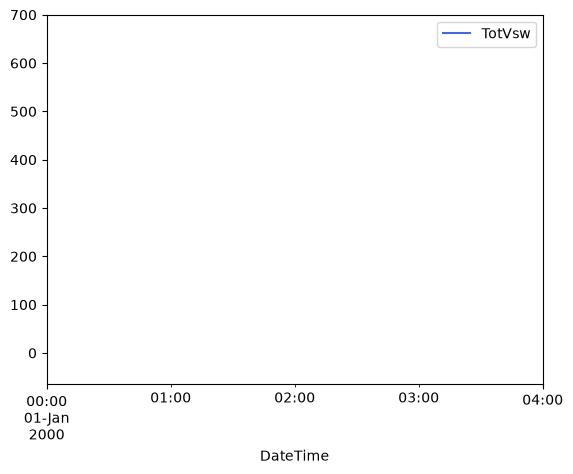

In [40]:
Columns = ["TotVsw"]#, "Vx_GSE", "Vy_GSE", "Vz_GSE"]
# xlim = [Start, End]
xlim = [ZoomStart, ZoomEnd]
# ylim = [250, 700]
ylim = [-65, 700]
color3 = "yellow"

fig, ax = plt.subplots()
# Plot timeseries with raw data
PlotVsw(dataTimeSerieses[0], Columns=["TotVsw"], XLim = xlim, YLim = ylim, Color = color1, Label = "Raw data")

# Plot timeseries with resampled data
# PlotVsw(resampledTS, Columns=["TotVsw"], XLim = xlim, YLim = ylim, Color = color2, Label = "Resampled at " + rate)
# PlotVsw(resampledTS2, Columns=["TotVsw"], XLim = xlim, YLim = ylim, Color = color3, Label = "Resampled at " + rate2)

# PlotVsw(dataTimeSerieses[0].resample("5min").sum(), Columns=["TotVsw"], XLim = xlim) # .sum() or no?

# Calculate variance of data
dataTimeSeriesVar = dataTimeSerieses[0].to_dataframe()["TotVsw"].var()
print( "Variance of raw data = " + str(dataTimeSeriesVar))
dataTimeSeriesVar = resampled["TotVsw"].var()
print( "Variance of resampled (" + rate + ") data = " + str(dataTimeSeriesVar))
dataTimeSeriesVar = resampled2["TotVsw"].var()
print( "Variance of resampled (" + rate2 + ") data = " + str(dataTimeSeriesVar))

# Plot "derivative" of data
derivative = []
dataToDerive = dataTimeSerieses[0].to_dataframe()["TotVsw"]
# dataToDerive = resampled["TotVsw"]
# dataToDerive = resampled2["TotVsw"]

for i in range(len(dataToDerive)-1):
    y_diff = dataToDerive.values[i+1]-dataToDerive.values[i]
    derivative.append(y_diff)


# derivative10 = []
d = {"TotVswDev": derivative}
derivative = pd.DataFrame(data=d, index=dataToDerive.index[0:-1])
print(derivative)
ax.plot(derivative, markersize=10)
# derivative.plot()
# for j in range(len(derivative)):
#     derivative10.append(derivative[j]*10)

# derivative.plot() # , alpha = 0.5)
# PlotVsw(derivative["TotVswDev"],  XLim = xlim, YLim = ylim, Color = color1, Label = "Raw data")
# plt.plot(dataToDerive.index[0:-1], derivative, color="green")


print("Caption: Raw data ("+str(color1) + ") and data resampled at " + rate + " resample rate ("+str(color2) + ") and "+ rate2 + " resample rate ("+str(color3) + ").")





File not saved


<Axes: xlabel='DateTime'>

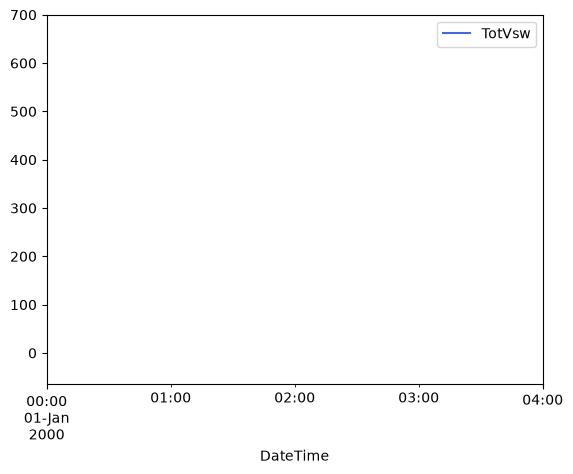

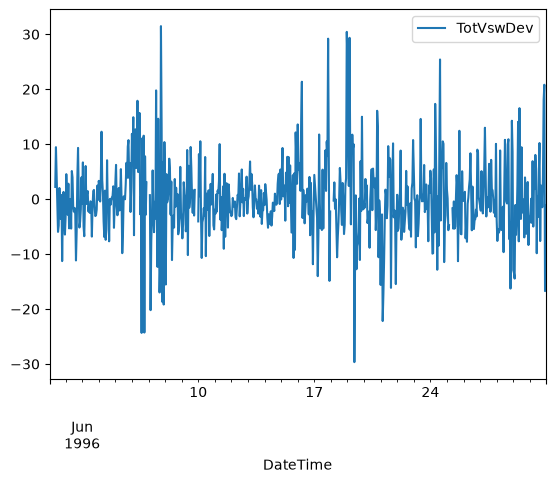

In [41]:
Columns = ["TotVsw"]#, "Vx_GSE", "Vy_GSE", "Vz_GSE"]
# xlim = [Start, End]
xlim = [ZoomStart, ZoomEnd]
# ylim = [250, 700]
ylim = [-65, 700]
color3 = "yellow"

fig, ax = plt.subplots()
# Plot timeseries with raw data
PlotVsw(dataTimeSerieses[0], Columns=["TotVsw"], XLim = xlim, YLim = ylim, Color = color1, Label = "Raw data")

# Plot "derivative" of data
derivative = []
dataToDerive = resampled["TotVsw"]

for i in range(len(dataToDerive)-1):
    y_diff = dataToDerive.values[i+1]-dataToDerive.values[i]
    derivative.append(y_diff)

d = {"TotVswDev": derivative}
derivative = pd.DataFrame(data=d, index=dataToDerive.index[0:-1])

# ax.plot(derivative)
# plt.plot(derivative)
derivative.plot()




In [42]:
maskFirst = Data.to_dataframe()[Variable].between(Thres-AbsThres, Thres+AbsThres) # get true/false array of data based on condition of values being between the threshold values


NameError: name 'Data' is not defined

[np.float64(nan), np.float64(nan), np.float64(nan), np.float64(0.0), np.float64(nan), np.float64(nan), np.float64(0.5939790595647878), np.float64(0.7327357369193805), np.float64(0.055424334272288434), np.float64(-1.5953385173386323), np.float64(1.2004397729608058), np.float64(-1.8054480009874396), np.float64(-0.19072367244041288), np.float64(-1.091781112626677), np.float64(4.286545039044427), np.float64(2.9295609462749894), np.float64(2.548106934165844), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(0.0), np.float64(nan), np.float64(nan), np.float64(-3.6154189200660767), np.float64(0.7441918464777473), np.float64(-0.0013932854918721205), np.float64(-2.2864873937772927), np.float64(3.7032783981778152), np.float64(nan), np.float64(nan), np.float64(-8.577206134062862), np.float64(-0.20218736254975056), np.float64(1.0252164475277823), np.float64(-3.7237886609311204), np.float64(-2.9339817375021653), np.floa

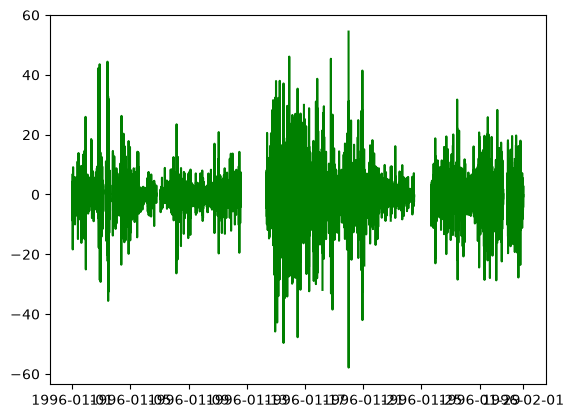

In [ ]:
# Plot "derivative" of data
derivative = []
for i in range(len(dataTimeSerieses[0].to_dataframe())-1):
    y_diff = dataTimeSerieses[0].to_dataframe()["TotVsw"].values[i+1]-dataTimeSerieses[0].to_dataframe()["TotVsw"].values[i]
    derivative.append(y_diff)

print(derivative)
# derivative10 = []

# for j in range(len(derivative)):
#     derivative10.append(derivative[j]*10)

plt.plot(dataTimeSerieses[0].to_dataframe().index[0:-1], derivative, color="green")
# plt.plot(dataTimeSerieses[0].to_dataframe().index[0:-1], derivative10, color="green")

# Plot steady and non-steady regions

# Time series with a lot of steadiness
# Time series with lots of change

# Time series at minimum
# Time series at maximum


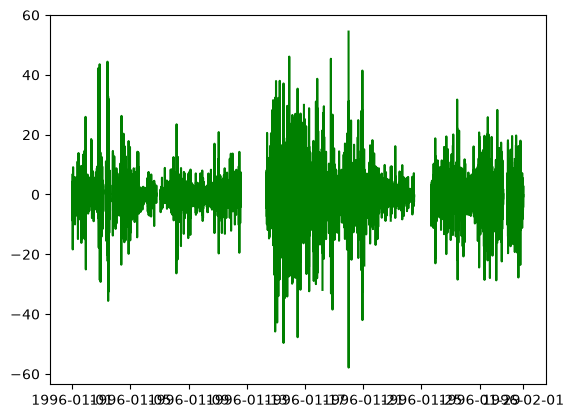

In [ ]:
plt.plot(dataTimeSerieses[0].to_dataframe().index[0:-1], derivative, color="green")
